# NeuroSignal-QC

## Interpretable Power-Line Interference Screening
### Intracranial EEG Signal Processing and Cross-Hospital Evaluation

**Research objective:** Investigate whether two interpretable
spectral measurements can identify power-line interference
in intracranial EEG recordings across recording institutions.

The study uses publicly available recordings from Mayo Clinic
and St. Anne's University Hospital (FNUSA).

The analysis is retrospective and exploratory.
It does not establish clinical safety or diagnostic validity.

---
## Phase 1 — Data Acquisition and Signal Inspection

We retrieve public EEG recordings and annotations,
inspect representative waveforms, and audit signal integrity.

The analyzed recordings are three-second EEG clips.
NEMAR provides a resampled representation at 1,000 Hz.

In [1]:
# ============================================================
# NEUROSIGNAL-QC
# Phase 1: Intracranial EEG Data Acquisition and Audit
# ============================================================

%pip -q install "zarr>=3,<4" s3fs pyarrow requests pandas numpy matplotlib scipy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


In [2]:
# ============================================================
# CELL 2: PROJECT INITIALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from IPython.display import display

# Project configuration
PROJECT_NAME = "NeuroSignal-QC"

DATASETS = {
    "Mayo": "nm000182",
    "FNUSA": "nm000183"
}

BASE_URL = "https://zarr.nemar.org"

HEADERS = {
    "User-Agent": "nemar-docs-recipe/1.0"
}

# Retrieve dataset indexes
indexes = {}

for hospital, dataset_id in DATASETS.items():

    url = f"{BASE_URL}/{dataset_id}/zarr/index.json"

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=60
    )

    response.raise_for_status()

    indexes[hospital] = response.json()

    print(f"\nHospital: {hospital}")
    print(f"Dataset: {dataset_id}")
    print(f"Available recording stores: {len(indexes[hospital]['stores'])}")

    print(
        "Dataset version/source commit:",
        indexes[hospital].get("source_commit", "Not reported")
    )

print("\nSuccessfully retrieved dataset indexes.")


Hospital: Mayo
Dataset: nm000182
Available recording stores: 257
Dataset version/source commit: a521c4b35cb2c48f1f38f9eea03866534eb654f4

Hospital: FNUSA
Dataset: nm000183
Available recording stores: 632
Dataset version/source commit: fa24384f3b9cd1cdbbba71468ed33fca1c8e2481

Successfully retrieved dataset indexes.


In [3]:
# ============================================================
# CELL 3: LOAD EEG ANNOTATIONS
# ============================================================

import pyarrow.fs as pafs
import pyarrow.parquet as pq

# Anonymous access to the public NEMAR S3 bucket
s3 = pafs.S3FileSystem(
    anonymous=True,
    region="us-east-2"
)

LABEL_MAP = {
    "physiology": "Physiological",
    "pathology": "Pathological",
    "noise": "Artifact",
    "powerline_50hz": "Power-line",
    "powerline_60hz": "Power-line"
}

events = {}

for hospital, dataset_id in DATASETS.items():

    if "events_parquet" not in indexes[hospital]:
        raise RuntimeError(
            f"No events.parquet advertised for {dataset_id}"
        )

    parquet_path = (
        f"nemar/{dataset_id}/zarr/events.parquet"
    )

    table = pq.read_table(
        parquet_path,
        filesystem=s3,
        columns=[
            "store_path",
            "subject",
            "group_name",
            "sample_index",
            "duration_s",
            "trial_type"
        ]
    )

    df = table.to_pandas()

    df["label"] = df["trial_type"].map(LABEL_MAP)

    df["sample_index"] = pd.to_numeric(
        df["sample_index"],
        errors="coerce"
    )

    events[hospital] = df

    print(f"\n{'=' * 45}")
    print(f"{hospital} ANNOTATION AUDIT")
    print(f"{'=' * 45}")

    print("Total annotation rows:", len(df))
    print("Unique subjects:", df["subject"].nunique())

    print("\nOriginal annotation categories:")
    print(df["trial_type"].value_counts(dropna=False))

    print("\nMapped categories:")
    print(df["label"].value_counts(dropna=False))

    print("\nFirst five records:")
    display(df.head())

print("\nAnnotation audit complete.")


Mayo ANNOTATION AUDIT
Total annotation rows: 155182
Unique subjects: 24

Original annotation categories:
trial_type
physiology        56730
powerline_60hz    41922
noise             41303
pathology         15227
Name: count, dtype: int64

Mapped categories:
label
Physiological    56730
Power-line       41922
Artifact         41303
Pathological     15227
Name: count, dtype: int64

First five records:


,store_path,subject,group_name,sample_index,duration_s,trial_type,label
0,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,0,3.0,noise,Artifact
1,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,3000,3.0,noise,Artifact
2,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,6000,3.0,noise,Artifact
3,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,9000,3.0,noise,Artifact
4,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,12000,3.0,noise,Artifact



FNUSA ANNOTATION AUDIT
Total annotation rows: 193118
Unique subjects: 14

Original annotation categories:
trial_type
physiology        94560
pathology         52470
noise             32599
powerline_50hz    13489
Name: count, dtype: int64

Mapped categories:
label
Physiological    94560
Pathological     52470
Artifact         32599
Power-line       13489
Name: count, dtype: int64

First five records:


,store_path,subject,group_name,sample_index,duration_s,trial_type,label
0,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,0,3.0,powerline_50hz,Power-line
1,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,3000,3.0,powerline_50hz,Power-line
2,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,6000,3.0,powerline_50hz,Power-line
3,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,9000,3.0,powerline_50hz,Power-line
4,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...,000,ieeg_1000hz,12000,3.0,powerline_50hz,Power-line



Annotation audit complete.


In [4]:
# ============================================================
# CELL 4: SELECT REPRESENTATIVE EEG CLIPS
# ============================================================

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

PREFERRED_SUBJECTS = {
    "Mayo": "sub-002",
    "FNUSA": "sub-006"
}

selected_clips = []

for hospital in DATASETS:

    df = events[hospital]

    # Build lookup for available recording stores
    store_lookup = {
        store["zarr"]: store
        for store in indexes[hospital]["stores"]
    }

    for category in CATEGORIES:

        candidates = df[
            (df["label"] == category)
            & (df["sample_index"].notna())
            & (df["sample_index"] >= 0)
        ].copy()

        # Prefer the selected participant
        preferred = candidates[
            candidates["subject"]
            == PREFERRED_SUBJECTS[hospital]
        ]

        search_groups = [preferred, candidates]

        chosen = None

        for group_df in search_groups:

            if chosen is not None:
                break

            for _, row in group_df.iterrows():

                store = store_lookup.get(
                    row["store_path"]
                )

                if store is None:
                    continue

                group = next(
                    (
                        g for g in store["groups"]
                        if g["name"] == row["group_name"]
                    ),
                    None
                )

                if group is None:
                    continue

                rate = float(group["rate"])
                start = int(row["sample_index"])

                # Every selected segment must contain 3 seconds
                required_samples = int(round(3 * rate))

                if (
                    start + required_samples
                    <= int(group["n_samples"])
                ):

                    chosen = {
                        "hospital": hospital,
                        "dataset_id": DATASETS[hospital],
                        "category": category,
                        "subject": row["subject"],
                        "store": store,
                        "group": group,
                        "start_sample": start
                    }

                    break

        if chosen is None:
            raise ValueError(
                f"No valid {category} segment found for {hospital}"
            )

        selected_clips.append(chosen)

# Selection summary
selection_summary = pd.DataFrame([
    {
        "Hospital": clip["hospital"],
        "Subject": clip["subject"],
        "Category": clip["category"],
        "Sampling rate (Hz)": clip["group"]["rate"],
        "Recording": clip["store"]["zarr"]
    }
    for clip in selected_clips
])

display(selection_summary)

print("\nSelected clips:", len(selected_clips))

,Hospital,Subject,Category,Sampling rate (Hz),Recording
0,Mayo,000,Physiological,1000.0,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...
1,Mayo,001,Pathological,1000.0,sub-001/ieeg/sub-001_task-MachineLearningEEG_r...
2,Mayo,000,Artifact,1000.0,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...
3,Mayo,004,Power-line,1000.0,sub-004/ieeg/sub-004_task-MachineLearningEEG_r...
4,FNUSA,002,Physiological,1000.0,sub-002/ieeg/sub-002_task-MachineLearningEEG_r...
5,FNUSA,001,Pathological,1000.0,sub-001/ieeg/sub-001_task-MachineLearningEEG_r...
6,FNUSA,002,Artifact,1000.0,sub-002/ieeg/sub-002_task-MachineLearningEEG_r...
7,FNUSA,000,Power-line,1000.0,sub-000/ieeg/sub-000_task-MachineLearningEEG_r...



Selected clips: 8


Loaded: Mayo | Physiological | 3000 samples | 1000 Hz
Loaded: Mayo | Pathological | 3000 samples | 1000 Hz
Loaded: Mayo | Artifact | 3000 samples | 1000 Hz
Loaded: Mayo | Power-line | 3000 samples | 1000 Hz
Loaded: FNUSA | Physiological | 3000 samples | 1000 Hz
Loaded: FNUSA | Pathological | 3000 samples | 1000 Hz
Loaded: FNUSA | Artifact | 3000 samples | 1000 Hz
Loaded: FNUSA | Power-line | 3000 samples | 1000 Hz


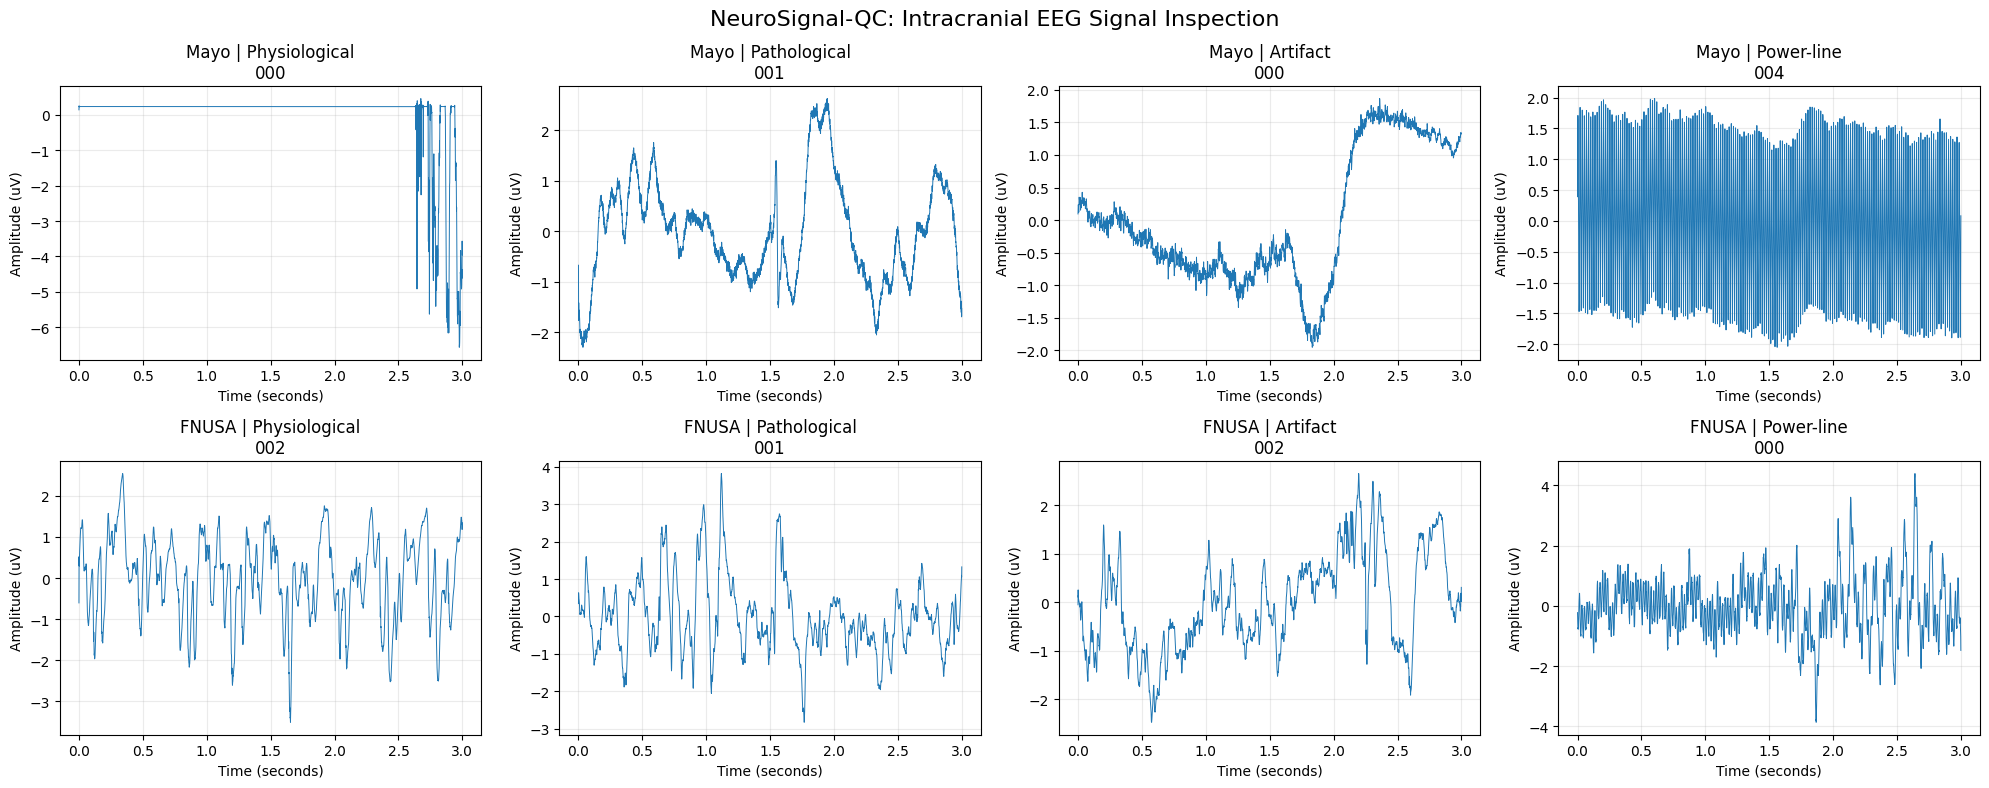

In [5]:
# ============================================================
# CELL 5: READ AND VISUALIZE REAL EEG SIGNALS
# ============================================================

import zarr
from zarr.storage import FsspecStore

waveforms = {}

for clip in selected_clips:

    hospital = clip["hospital"]
    category = clip["category"]
    dataset_id = clip["dataset_id"]

    store_path = clip["store"]["zarr"]

    s3_uri = (
        f"s3://nemar/{dataset_id}/zarr/{store_path}"
    )

    # Open the remote signal store
    remote_store = FsspecStore.from_url(
        s3_uri,
        storage_options={
            "anon": True,
            "client_kwargs": {
                "region_name": "us-east-2"
            }
        }
    )

    root = zarr.open_group(
        store=remote_store,
        mode="r",
        zarr_format=3
    )

    group_name = clip["group"]["name"]

    group = root[group_name]

    signal = group["0"]

    fs = float(group.attrs["rate"])

    start = clip["start_sample"]
    n_samples = int(round(3 * fs))

    # Read only the required 3-second signal window
    digital_signal = np.asarray(
        signal[0:1, start:start + n_samples],
        dtype=np.float64
    ).ravel()

    # Convert digital signal to physical units
    scale = float(signal.attrs["scale"][0])
    offset = float(signal.attrs["offset"][0])

    eeg = digital_signal * scale + offset

    channel_info = group.attrs["channels"][0]

    unit = channel_info.get("unit", "unknown")

    time = np.arange(len(eeg)) / fs

    waveforms[(hospital, category)] = {
        "signal": eeg,
        "time": time,
        "sampling_rate": fs,
        "unit": unit,
        "subject": clip["subject"],
        "source": store_path
    }

    print(
        f"Loaded: {hospital} | {category} | "
        f"{len(eeg)} samples | {fs:g} Hz"
    )

# ------------------------------------------------------------
# Plot EEG waveforms
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 8)
)

for row, hospital in enumerate(DATASETS):

    for col, category in enumerate(CATEGORIES):

        data = waveforms[(hospital, category)]

        ax = axes[row, col]

        ax.plot(
            data["time"],
            data["signal"],
            linewidth=0.7
        )

        ax.set_title(
            f"{hospital} | {category}\n"
            f"{data['subject']}"
        )

        ax.set_xlabel("Time (seconds)")

        ax.set_ylabel(
            f"Amplitude ({data['unit']})"
        )

        ax.grid(
            alpha=0.25
        )

fig.suptitle(
    "NeuroSignal-QC: Intracranial EEG Signal Inspection",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# CELL 6: INITIAL SIGNAL QUALITY AUDIT
# ============================================================

quality_records = []

for (hospital, category), data in waveforms.items():

    signal = data["signal"]

    finite_mask = np.isfinite(signal)

    if not finite_mask.any():
        raise ValueError(
            f"No finite samples: {hospital}, {category}"
        )

    finite_signal = signal[finite_mask]

    record = {
        "Hospital": hospital,
        "Subject": data["subject"],
        "Category": category,
        "Sampling Rate": data["sampling_rate"],
        "Duration (s)": len(signal) / data["sampling_rate"],
        "Unit": data["unit"],
        "Mean": np.mean(finite_signal),
        "Std Dev": np.std(finite_signal),
        "Peak-to-Peak": np.ptp(finite_signal),
        "Nonfinite Samples": (~finite_mask).sum()
    }

    quality_records.append(record)

quality_df = pd.DataFrame(quality_records)

display(
    quality_df.round(4)
)

# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------

assert len(waveforms) == 8, \
    "Expected eight selected EEG clips."

for key, data in waveforms.items():

    expected = int(
        round(3 * data["sampling_rate"])
    )

    assert len(data["signal"]) == expected, \
        f"Unexpected signal length for {key}"

print("\nPhase 1 signal-length checks passed.")
print("Eight EEG recordings inspected successfully.")

,Hospital,Subject,Category,Sampling Rate,Duration (s),Unit,Mean,Std Dev,Peak-to-Peak,Nonfinite Samples
0,Mayo,000,Physiological,1000.0,3.0,uV,-0.0001,0.9969,7.0227,0
1,Mayo,001,Pathological,1000.0,3.0,uV,0.0003,0.9985,4.9245,0
2,Mayo,000,Artifact,1000.0,3.0,uV,-0.0002,0.9998,3.8248,0
3,Mayo,004,Power-line,1000.0,3.0,uV,-0.0001,1.0005,4.0357,0
4,FNUSA,002,Physiological,1000.0,3.0,uV,-0.0003,1.0002,6.0460,0
5,FNUSA,001,Pathological,1000.0,3.0,uV,-0.0001,1.0000,6.6442,0
6,FNUSA,002,Artifact,1000.0,3.0,uV,-0.0000,1.0000,5.1287,0
7,FNUSA,000,Power-line,1000.0,3.0,uV,0.0002,1.0003,8.2595,0



Phase 1 signal-length checks passed.
Eight EEG recordings inspected successfully.


### Signal Normalization and Sampling Audit

The initial recordings exhibited approximately zero mean
and unit standard deviation.

We investigate whether this pattern persists across
additional segments and inspect the sampling metadata.

Because the distributed signals appear standardized,
amplitude values should not be interpreted as
calibrated absolute microvolt measurements.

In [7]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 1 — CELL 7
# Signal Normalization and Sampling Audit
# ============================================================

import numpy as np
import pandas as pd
import zarr
from zarr.storage import FsspecStore

audit_records = []

print("=" * 65)
print("NEUROSIGNAL-QC — SIGNAL NORMALIZATION AUDIT")
print("=" * 65)

for hospital, dataset_id in DATASETS.items():

    df = events[hospital]

    # Select the first available recording
    first_event = df.iloc[0]

    store_path = first_event["store_path"]
    group_name = first_event["group_name"]

    # Select eight annotated segments from the same recording
    candidates = df[
        (df["store_path"] == store_path)
        & (df["group_name"] == group_name)
    ].sort_values("sample_index").head(8)

    # Connect to the remote recording
    s3_uri = (
        f"s3://nemar/{dataset_id}/zarr/{store_path}"
    )

    remote_store = FsspecStore.from_url(
        s3_uri,
        storage_options={
            "anon": True,
            "client_kwargs": {
                "region_name": "us-east-2"
            }
        }
    )

    root = zarr.open_group(
        store=remote_store,
        mode="r",
        zarr_format=3
    )

    group = root[group_name]
    signal_array = group["0"]

    # Sampling metadata
    served_fs = float(group.attrs["rate"])

    source_fs = signal_array.attrs.get(
        "source_rate_hz",
        group.attrs.get("source_rate_hz", "Not reported")
    )

    # Signal conversion parameters
    scale = float(signal_array.attrs["scale"][0])
    offset = float(signal_array.attrs["offset"][0])

    print(f"\nHospital: {hospital}")
    print(f"Served sampling rate: {served_fs} Hz")
    print(f"Source sampling rate: {source_fs} Hz")
    print(f"Scale: {scale}")
    print(f"Offset: {offset}")

    for segment_number, (_, row) in enumerate(
        candidates.iterrows(), start=1
    ):

        start = int(row["sample_index"])

        n_samples = int(
            round(float(row["duration_s"]) * served_fs)
        )

        # Retrieve the EEG segment
        digital = np.asarray(
            signal_array[
                0,
                start:start + n_samples
            ],
            dtype=np.float64
        )

        # Convert using stored metadata
        eeg = digital * scale + offset

        if len(eeg) != n_samples:
            raise ValueError(
                f"Incomplete segment: {hospital}, "
                f"segment {segment_number}"
            )

        audit_records.append({
            "Hospital": hospital,
            "Segment": segment_number,
            "Category": row["trial_type"],
            "Mean": np.mean(eeg),
            "Standard Deviation": np.std(eeg),
            "Peak-to-Peak": np.ptp(eeg),
            "Approximately Standardized": (
                abs(np.mean(eeg)) < 0.02
                and abs(np.std(eeg) - 1) < 0.02
            )
        })

# ============================================================
# RESULTS
# ============================================================

normalization_df = pd.DataFrame(audit_records)

print("\n" + "=" * 65)
print("SEGMENT-LEVEL STATISTICS")
print("=" * 65)

display(normalization_df.round(5))

print("\n" + "=" * 65)
print("NORMALIZATION SUMMARY")
print("=" * 65)

summary = normalization_df.groupby("Hospital").agg(
    Segments=("Segment", "count"),
    Mean_Std=("Standard Deviation", "mean"),
    Min_Std=("Standard Deviation", "min"),
    Max_Std=("Standard Deviation", "max"),
    Approximately_Standardized=(
        "Approximately Standardized",
        "sum"
    )
)

display(summary.round(5))

print("\nAudit complete.")

NEUROSIGNAL-QC — SIGNAL NORMALIZATION AUDIT

Hospital: Mayo
Served sampling rate: 1000.0 Hz
Source sampling rate: 5000.0 Hz
Scale: 0.00015410132178813476
Offset: 0.31064104146076676

Hospital: FNUSA
Served sampling rate: 1000.0 Hz
Source sampling rate: 5000.0 Hz
Scale: 0.00016008410833535255
Offset: -0.854108752298389

SEGMENT-LEVEL STATISTICS


,Hospital,Segment,Category,Mean,Standard Deviation,Peak-to-Peak,Approximately Standardized
0,Mayo,1,noise,-0.00020,0.99984,3.82479,True
1,Mayo,2,noise,0.00036,1.00002,3.38329,True
2,Mayo,3,noise,0.00005,0.99970,3.60181,True
3,Mayo,4,noise,-0.00039,1.00007,4.14563,True
4,Mayo,5,noise,0.00002,0.99958,4.70286,True
5,Mayo,6,noise,-0.00014,0.99960,4.09139,True
6,Mayo,7,noise,0.00056,0.99910,5.76493,True
7,Mayo,8,noise,-0.00018,0.99965,4.47695,True
8,FNUSA,1,powerline_50hz,0.00016,1.00025,8.25954,True
9,FNUSA,2,powerline_50hz,0.00013,1.00008,8.05815,True



NORMALIZATION SUMMARY


,Segments,Mean_Std,Min_Std,Max_Std,Approximately_Standardized
Hospital,,,,,
FNUSA,8,1.0002,0.99979,1.00051,8
Mayo,8,0.9997,0.99910,1.00007,8



Audit complete.
